# Prediksi Kegagalan Mahasiswa

Flattening Data

In [ ]:
import pandas as pd
import numpy as np
from functools import reduce

df_logs = pd.read_csv('mdl_logstore_standard_log.csv')
feat_logs = df_logs.groupby(['userid', 'courseid']).agg(
    total_clicks=('id', 'count')
).reset_index()

df_hvp = pd.read_csv('mdl_hvp.csv')
df_hvp_res = pd.read_csv('mdl_hvp_xapi_results.csv')
df_hvp_merged = pd.merge(df_hvp_res, df_hvp, left_on='content_id', right_on='id', suffixes=('', '_ref'))
feat_hvp = df_hvp_merged.groupby(['user_id', 'course']).agg(
    total_hvp_interactions=('id', 'count')
).reset_index().rename(columns={'user_id': 'userid', 'course': 'courseid'})

df_forum_disc = pd.read_csv('mdl_forum_discussions.csv')
feat_forum_disc = df_forum_disc.groupby(['userid', 'course']).agg(
    total_forum_discussions=('id', 'count')
).reset_index().rename(columns={'course': 'courseid'})

df_forum_posts = pd.read_csv('mdl_forum_posts.csv')
df_forum_merged = pd.merge(df_forum_posts, df_forum_disc[['id', 'course']], left_on='discussion', right_on='id', suffixes=('', '_ref'))
feat_forum_posts = df_forum_merged.groupby(['userid', 'course']).agg(
    total_forum_posts=('id', 'count')
).reset_index().rename(columns={'course': 'courseid'})

feat_forum_activity = pd.merge(feat_forum_disc, feat_forum_posts, on=['userid', 'courseid'], how='outer').fillna(0)
feat_forum_activity['total_forum_activity'] = feat_forum_activity['total_forum_discussions'] + feat_forum_activity['total_forum_posts']

feat_forum_activity = feat_forum_activity[['userid', 'courseid', 'total_forum_activity']]


print("\n--- TAHAP 2: EKSTRAKSI TIGA PILAR FITUR NILAI (PREDIKTOR) ---")

df_assign_grades = pd.read_csv('mdl_assign_grades.csv')
df_assign = pd.read_csv('mdl_assign.csv')
df_ag_merged = pd.merge(df_assign_grades, df_assign, left_on='assignment', right_on='id', suffixes=('', '_ref'))
feat_assign_grade = df_ag_merged.groupby(['userid', 'course']).agg(
    assign_grade=('grade', 'mean')
).reset_index().rename(columns={'course': 'courseid'})

df_quiz_grades = pd.read_csv('mdl_quiz_grades.csv')
df_quiz = pd.read_csv('mdl_quiz.csv')
df_qg_merged = pd.merge(df_quiz_grades, df_quiz, left_on='quiz', right_on='id', suffixes=('', '_ref'))
feat_quiz_grade = df_qg_merged.groupby(['userid', 'course']).agg(
    quiz_grade=('grade', 'mean')
).reset_index().rename(columns={'course': 'courseid'})

df_forum_grades = pd.read_csv('mdl_forum_grades.csv')
df_grade_items = pd.read_csv('mdl_grade_items.csv')
df_grade_grades = pd.read_csv('mdl_grade_grades.csv')

df_gi_forum = df_grade_items[df_grade_items['itemmodule'] == 'forum']
df_fg_rules = pd.merge(df_forum_grades, df_gi_forum, left_on='forum', right_on='iteminstance', suffixes=('', '_item'))
df_fg_rules = df_fg_rules.rename(columns={'id_item': 'itemid'})
df_fg_final = pd.merge(df_fg_rules, df_grade_grades, on=['userid', 'itemid'], suffixes=('', '_gg'))

df_fg_final = df_fg_final[df_fg_final['excluded'] != 1]
df_fg_final['clean_forum_grade'] = (df_fg_final['grade'] / df_fg_final['rawgrademax']) * 100
feat_forum_grade = df_fg_final.groupby(['userid', 'courseid']).agg(
    forum_grade=('clean_forum_grade', 'mean')
).reset_index()


print("\n--- TAHAP 3: PENGGABUNGAN MATRIKS & PEMBENTUKAN TARGET ---")

dataframes = [
    feat_logs, feat_hvp, feat_forum_activity,
    feat_assign_grade, feat_quiz_grade, feat_forum_grade
]

df_master = reduce(lambda left, right: pd.merge(left, right, on=['userid', 'courseid'], how='outer'), dataframes)
df_master = df_master.fillna(0)

df_master['combined_performance'] = df_master[['assign_grade', 'quiz_grade', 'forum_grade']].mean(axis=1)
df_master['is_at_risk'] = (df_master['combined_performance'] < 60).astype(int)

df_master.to_csv('dataset_gabungan_baru.csv', index=False)
print("\n[BERHASIL] Berkas 'dataset_gabungan_baru.csv' berhasil diperbarui dengan struktur fitur yang dioptimasi!")

Memproses 279 baris data mahasiswa yang valid.
Daftar 6 Fitur Prediktor Final: ['total_clicks', 'total_hvp_interactions', 'total_forum_activity', 'assign_grade', 'quiz_grade', 'forum_grade']
Akurasi Data Training: 99.04%
Akurasi Data Testing : 98.57%

Laporan Klasifikasi Model Final:
              precision    recall  f1-score   support

           0       1.00      0.96      0.98        24
           1       0.98      1.00      0.99        46

    accuracy                           0.99        70
   macro avg       0.99      0.98      0.98        70
weighted avg       0.99      0.99      0.99        70

[SUKSES] Artefak '.pkl' versi final (6 Fitur) berhasil diperbarui!


,Nama Fitur,Bobot (%),Penjelasan Teknis / Akademis
0,forum_grade,32.21,Rata-rata nilai aktivitas diskusi forum kelomp...
1,assign_grade,22.62,Rata-rata nilai penugasan murni (tugas) milik ...
2,total_forum_activity,18.54,Total agregat keaktifan partisipasi mahasiswa ...
3,quiz_grade,15.31,Rata-rata nilai kuis murni milik mahasiswa
4,total_clicks,11.12,Total aktivitas klik atau navigasi keaktifan m...
5,total_hvp_interactions,0.21,Total volume rekam jejak interaksi pada materi...


/tmp/ipykernel_2378/2209439333.py:62: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Bobot (%)', y='Nama Fitur', data=df_bobot, palette='magma')


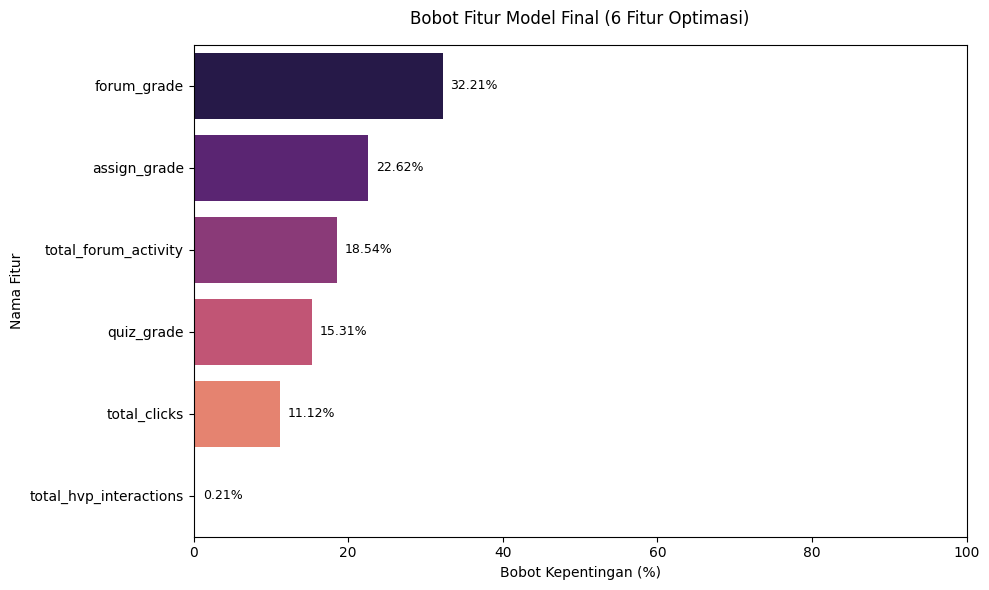

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score
import joblib
from IPython.display import display

df_clean = pd.read_csv('dataset_gabungan_baru.csv')
print(f"Memproses {len(df_clean)} baris data mahasiswa yang valid.")

kolom_dibuang = ['userid', 'courseid', 'combined_performance', 'is_at_risk']
X = df_clean.drop(columns=kolom_dibuang)
y = df_clean['is_at_risk']

print(f"Daftar {len(X.columns)} Fitur Prediktor Final: {list(X.columns)}")
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.25, random_state=42, stratify=y
)
rf_model = RandomForestClassifier(n_estimators=100, max_depth=3, min_samples_split=5, random_state=42)
rf_model.fit(X_train, y_train)

y_pred_train = rf_model.predict(X_train)
y_pred_test = rf_model.predict(X_test)
print(f"Akurasi Data Training: {accuracy_score(y_train, y_pred_train) * 100:.2f}%")
print(f"Akurasi Data Testing : {accuracy_score(y_test, y_pred_test) * 100:.2f}%")

print("\nLaporan Klasifikasi Model Final:")
print(classification_report(y_test, y_pred_test))

joblib.dump(rf_model, 'smart_lmsx_model_final.pkl')
joblib.dump(scaler, 'scaler.pkl')
print("[SUKSES] Artefak '.pkl' versi final (6 Fitur) berhasil diperbarui!")


kamus_penjelasan = {
    'total_clicks': 'Total aktivitas klik atau navigasi keaktifan mahasiswa di dalam LMS Moodle',
    'total_hvp_interactions': 'Total volume rekam jejak interaksi pada materi pembelajaran multimedia H5P',
    'total_forum_activity': 'Total agregat keaktifan partisipasi mahasiswa di forum (gabungan inisiatif topik dan komentar)',
    'assign_grade': 'Rata-rata nilai penugasan murni (tugas) milik mahasiswa',
    'quiz_grade': 'Rata-rata nilai kuis murni milik mahasiswa',
    'forum_grade': 'Rata-rata nilai aktivitas diskusi forum kelompok/mandiri milik mahasiswa'
}

importances = rf_model.feature_importances_
df_bobot = pd.DataFrame({
    'Nama Fitur': X.columns,
    'Bobot (%)': np.round(importances * 100, 2)
})
df_bobot['Penjelasan Teknis / Akademis'] = df_bobot['Nama Fitur'].map(kamus_penjelasan)
df_bobot = df_bobot.sort_values(by='Bobot (%)', ascending=False).reset_index(drop=True)

display(df_bobot)

plt.figure(figsize=(10, 6))
sns.barplot(x='Bobot (%)', y='Nama Fitur', data=df_bobot, palette='magma')
plt.title('Bobot Fitur Model Final (6 Fitur Optimasi)', fontsize=12, pad=15)
plt.xlabel('Bobot Kepentingan (%)')
plt.xlim(0, 100)

for index, value in enumerate(df_bobot['Bobot (%)']):
    plt.text(value + 1, index, f'{value}%', va='center', fontsize=9)

plt.tight_layout()
plt.show()

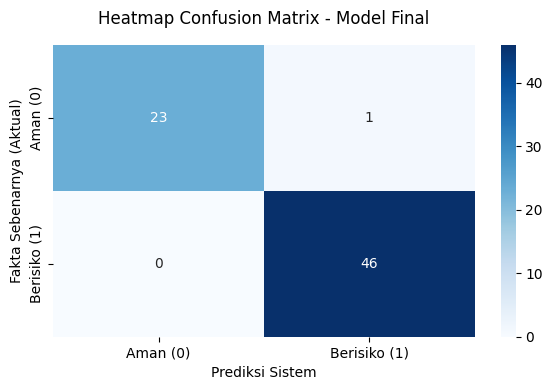

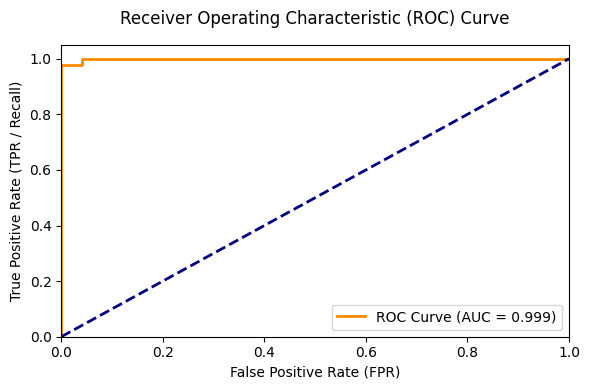

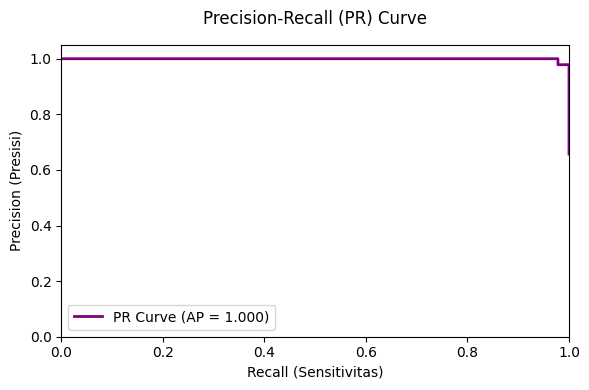

In [2]:
from sklearn.metrics import confusion_matrix, roc_curve, auc, precision_recall_curve, average_precision_score
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_test, y_pred_test)

plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Aman (0)', 'Berisiko (1)'],
            yticklabels=['Aman (0)', 'Berisiko (1)'])
plt.title('Heatmap Confusion Matrix - Model Final', pad=15)
plt.xlabel('Prediksi Sistem')
plt.ylabel('Fakta Sebenarnya (Aktual)')
plt.tight_layout()
plt.show()

y_prob_test = rf_model.predict_proba(X_test)[:, 1]

fpr, tpr, thresholds_roc = roc_curve(y_test, y_prob_test)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(6, 4))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC Curve (AUC = {roc_auc:.3f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR / Recall)')
plt.title('Receiver Operating Characteristic (ROC) Curve', pad=15)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

precision, recall, thresholds_pr = precision_recall_curve(y_test, y_prob_test)
ap_score = average_precision_score(y_test, y_prob_test)

plt.figure(figsize=(6, 4))
plt.plot(recall, precision, color='purple', lw=2, label=f'PR Curve (AP = {ap_score:.3f})')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Recall (Sensitivitas)')
plt.ylabel('Precision (Presisi)')
plt.title('Precision-Recall (PR) Curve', pad=15)
plt.legend(loc="lower left")
plt.tight_layout()
plt.show()

In [3]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd

models = {
    "Logistic Regression": LogisticRegression(random_state=42),
    "Decision Tree": DecisionTreeClassifier(random_state=42, max_depth=3),
    "Support Vector Machine (SVM)": SVC(random_state=42),
    "Random Forest (Model Anda)": RandomForestClassifier(n_estimators=100, max_depth=3, min_samples_split=5, random_state=42)
}

hasil_evaluasi = []

for nama_model, model in models.items():
    model.fit(X_train, y_train)
    y_pred_test = model.predict(X_test)

    hasil_evaluasi.append({
        "Algoritma": nama_model,
        "Akurasi (%)": round(accuracy_score(y_test, y_pred_test) * 100, 2),
        "Precision (%)": round(precision_score(y_test, y_pred_test) * 100, 2),
        "Recall (%)": round(recall_score(y_test, y_pred_test) * 100, 2),
        "F1-Score (%)": round(f1_score(y_test, y_pred_test) * 100, 2)
    })

df_komparasi = pd.DataFrame(hasil_evaluasi)
display(df_komparasi)

,Algoritma,Akurasi (%),Precision (%),Recall (%),F1-Score (%)
0,Logistic Regression,95.71,100.00,93.48,96.63
1,Decision Tree,100.00,100.00,100.00,100.00
2,Support Vector Machine (SVM),91.43,100.00,86.96,93.02
3,Random Forest (Model Anda),98.57,97.87,100.00,98.92


In [4]:
from google.colab import sheets
sheet = sheets.InteractiveSheet(df=df_komparasi)

https://docs.google.com/spreadsheets/d/1E0rFHe1vVILaAteimI-79t27CaHNi7ZCs7MUx5UVGdw/edit#gid=0


In [5]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# 1. Load Data
df = pd.read_csv('dataset_gabungan_baru.csv')
y = df['is_at_risk']

# 2. SKENARIO 1: Model Usulan (Dengan Fitur Forum - 6 Fitur Lengkap)
X_usulan = df.drop(columns=['userid', 'courseid', 'combined_performance', 'is_at_risk'])
scaler = StandardScaler()
X_usulan_scaled = scaler.fit_transform(X_usulan)
X_train_u, X_test_u, y_train_u, y_test_u = train_test_split(X_usulan_scaled, y, test_size=0.25, random_state=42, stratify=y)

rf_usulan = RandomForestClassifier(n_estimators=100, max_depth=3, min_samples_split=5, random_state=42)
rf_usulan.fit(X_train_u, y_train_u)
y_pred_u = rf_usulan.predict(X_test_u)

print("=== SKENARIO 1: MENGGUNAKAN FITUR FORUM (6 FITUR) ===")
print(f"Akurasi: {accuracy_score(y_test_u, y_pred_u)*100:.2f}%")
print(f"Precision: {precision_score(y_test_u, y_pred_u)*100:.2f}%")
print(f"Recall: {recall_score(y_test_u, y_pred_u)*100:.2f}%")
print(f"F1-Score: {f1_score(y_test_u, y_pred_u)*100:.2f}%\n")

# 3. SKENARIO 2: Model Basis (Tanpa Fitur Forum - Hanya 4 Fitur)
# Kita membuang 'total_forum_activity' dan 'forum_grade'
X_basis = df.drop(columns=['userid', 'courseid', 'combined_performance', 'is_at_risk', 'total_forum_activity', 'forum_grade'])
X_basis_scaled = scaler.fit_transform(X_basis)
X_train_b, X_test_b, y_train_b, y_test_b = train_test_split(X_basis_scaled, y, test_size=0.25, random_state=42, stratify=y)

rf_basis = RandomForestClassifier(n_estimators=100, max_depth=3, min_samples_split=5, random_state=42)
rf_basis.fit(X_train_b, y_train_b)
y_pred_b = rf_basis.predict(X_test_b)

print("=== SKENARIO 2: TANPA FITUR FORUM (4 FITUR SAJA) ===")
print(f"Akurasi: {accuracy_score(y_test_b, y_pred_b)*100:.2f}%")
print(f"Precision: {precision_score(y_test_b, y_pred_b)*100:.2f}%")
print(f"Recall: {recall_score(y_test_b, y_pred_b)*100:.2f}%")
print(f"F1-Score: {f1_score(y_test_b, y_pred_b)*100:.2f}%")

=== SKENARIO 1: MENGGUNAKAN FITUR FORUM (6 FITUR) ===
Akurasi: 98.57%
Precision: 97.87%
Recall: 100.00%
F1-Score: 98.92%

=== SKENARIO 2: TANPA FITUR FORUM (4 FITUR SAJA) ===
Akurasi: 85.71%
Precision: 89.13%
Recall: 89.13%
F1-Score: 89.13%
